# Phase 1: Casualty Severity Classification
## Part A: Data import, audit, cleaning, split and EDA foundations
Unit of analysis: **one casualty**. Target: `casualty_severity` (1 = Fatal, 2 = Serious, 3 = Slight).

## Step 0: Setup

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

SEED = 42
DATA_DIR = '/content/'   # change if your CSVs live elsewhere

## Step 1: Import and audit each table
A table's **key** is the set of columns that should identify a row uniquely. Zero key duplicates means joins will behave.

In [ ]:
collision_df = pd.read_csv(DATA_DIR + 'dft-road-casualty-statistics-collision-2025.csv', low_memory=False)
casualty_df  = pd.read_csv(DATA_DIR + 'dft-road-casualty-statistics-casualty-2025.csv',  low_memory=False)
vehicle_df   = pd.read_csv(DATA_DIR + 'dft-road-casualty-statistics-vehicle-2025.csv',   low_memory=False)

def audit_table(df, name, key):
    print(f'{name:10s}: {len(df):>8,} rows x {df.shape[1]} cols | '
          f'exact dups: {df.duplicated().sum()} | key dups: {df.duplicated(key).sum()}')

audit_table(collision_df, 'collision', ['collision_index'])
audit_table(casualty_df,  'casualty',  ['collision_index', 'vehicle_reference', 'casualty_reference'])
audit_table(vehicle_df,   'vehicle',   ['collision_index', 'vehicle_reference'])

collision :  101,525 rows x 44 cols | exact dups: 0 | key dups: 0
casualty  :  127,883 rows x 24 cols | exact dups: 0 | key dups: 0
vehicle   :  183,948 rows x 32 cols | exact dups: 0 | key dups: 0


## Step 2: Merge to the casualty grain
- `validate='many_to_one'` makes pandas raise an error if the right-hand table has duplicate keys (prevents silent row explosion).
- `indicator` reports casualties that found no match.
- The `assert` is a tripwire: the row count must never change.
- Pedestrians are linked to the **striking** vehicle, so their vehicle fields describe that vehicle and its driver.

In [ ]:
veh_slim = vehicle_df.drop(columns=['collision_year', 'collision_ref_no'])
col_slim = collision_df.drop(columns=['collision_year', 'collision_ref_no'])

master_df = casualty_df.merge(
    veh_slim, on=['collision_index', 'vehicle_reference'], how='left',
    validate='many_to_one', suffixes=('_cas', '_veh'), indicator='_veh_match')
print(master_df['_veh_match'].value_counts())

master_df = master_df.drop(columns='_veh_match').merge(
    col_slim, on='collision_index', how='left',
    validate='many_to_one', indicator='_col_match')
print(master_df['_col_match'].value_counts())

master_df = master_df.drop(columns='_col_match')
assert len(master_df) == len(casualty_df), 'Row count changed. The join is wrong.'
print('master_df shape:', master_df.shape)

_veh_match
both          127883
left_only          0
right_only         0
Name: count, dtype: int64
_col_match
both          127883
left_only          0
right_only         0
Name: count, dtype: int64
master_df shape: (127883, 93)


## Step 3: What does "missing" look like here?
There are no real `NaN`s: the DfT codes missing values as `-1`. That is why `info()` and `isnull().sum()` report zero nulls.

In [ ]:
def sentinel_audit(df):
    out = pd.DataFrame({'nan_%':    df.isna().mean() * 100,
                        'minus1_%': (df == -1).mean() * 100,
                        'n_unique': df.nunique()})
    out['missing_%'] = out['nan_%'] + out['minus1_%']
    return out.sort_values('missing_%', ascending=False).round(1)

sa = sentinel_audit(master_df)
sa[sa['missing_%'] > 0]

,nan_%,minus1_%,n_unique,missing_%
age_of_vehicle,0.0,100.0,1,100.0
local_authority_district,0.0,100.0,1,100.0
vehicle_manoeuvre_historic,0.0,87.7,20,87.7
journey_purpose_of_driver_historic,0.0,87.4,7,87.4
junction_detail_historic,0.0,86.4,11,86.4
special_conditions_at_site,0.0,86.4,10,86.4
pedestrian_crossing_physical_facilities_historic,0.0,86.4,8,86.4
pedestrian_crossing_human_control_historic,0.0,86.4,5,86.4
carriageway_hazards_historic,0.0,86.4,8,86.4
vehicle_location_restricted_lane_historic,0.0,86.4,12,86.4


## Step 3b: Load the DfT data guide: labels, and the *hidden* missing values
`-1` is not the only way the data says "I don't know". The guide also defines codes such as `9` / `99` = "unknown (self reported)".
Which codes mean "unknown" depends on the field (`9` is "Unknown" for weather, but `9` is "Car" for vehicle type), so we read the rules from the guide instead of guessing.

Note: the guide lists casualty_type code 23 twice. The data contains code 33 (1,227 casualties), so the second 23 (Personal Powered Transporter) is a typo for 33 and is corrected below.

In [ ]:
GUIDE_FILE = DATA_DIR + 'dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx'
guide = pd.read_excel(GUIDE_FILE, sheet_name='2024_code_list')
guide = guide[guide['table'].isin(['collision', 'vehicle', 'casualty'])].copy()
guide['code'] = pd.to_numeric(guide['code/format'], errors='coerce')
guide = guide.dropna(subset=['code', 'label'])

# Fix the guide's typo (see note above), then keep one row per (table, field, code)
typo = ((guide['table'] == 'casualty') & (guide['field name'] == 'casualty_type')
        & (guide['label'] == 'Personal Powered Transporter'))
guide.loc[typo, 'code'] = 33
guide = guide.drop_duplicates(['table', 'field name', 'code'])

def is_unknown(label):
    l = str(label).strip().lower()
    return l.startswith('unknown') or l.startswith('data missing') or l == 'undefined'
# (this keeps real categories such as "Darkness - lighting unknown" or "Motorcycle - unknown cc")

# Which table does each merged column come from?
table_of = {}
for tname, d in [('casualty', casualty_df), ('vehicle', vehicle_df), ('collision', collision_df)]:
    for c in d.columns:
        table_of.setdefault(c, tname)
table_of['escooter_flag_cas'], table_of['escooter_flag_veh'] = 'casualty', 'vehicle'
field_of = {'escooter_flag_cas': 'escooter_flag', 'escooter_flag_veh': 'escooter_flag'}

LABELS, UNKNOWN_CODES = {}, {}
for col in master_df.columns:
    sub = guide[(guide['table'] == table_of.get(col)) & (guide['field name'] == field_of.get(col, col))]
    if len(sub):
        LABELS[col] = {int(r.code): r.label for r in sub.itertuples()}
        UNKNOWN_CODES[col] = sorted({int(r.code) for r in sub.itertuples() if is_unknown(r.label)} | {-1})
print(f'Label maps built for {len(LABELS)} columns')

# Hidden missingness: "unknown" codes other than -1
hidden = pd.Series({c: master_df[c].isin([k for k in codes if k != -1]).mean() * 100
                    for c, codes in UNKNOWN_CODES.items() if c in master_df and len(codes) > 1})
display(hidden[hidden > 0].sort_values(ascending=False).round(2)
        .rename('hidden unknown % (codes other than -1)').to_frame())

Label maps built for 70 columns


,hidden unknown % (codes other than -1)
skidding_and_overturning,6.63
vehicle_left_hand_drive,6.60
hit_object_in_carriageway,6.57
vehicle_direction_to,6.52
vehicle_direction_from,6.52
vehicle_location_restricted_lane,6.44
vehicle_leaving_carriageway,6.39
hit_object_off_carriageway,6.34
vehicle_manoeuvre,6.19
pedestrian_movement,4.35


## Step 4: Column roles (your data dictionary in code), decode unknown codes, parse time
Integer dtype does **not** mean numeric. `vehicle_type` and `road_type` are labels stored as numbers.

In [ ]:
TARGET   = 'casualty_severity'
ID_COLS  = ['collision_index', 'collision_ref_no', 'vehicle_reference', 'casualty_reference', 'collision_year']
LEAKAGE  = ['enhanced_casualty_severity', 'casualty_injury_based',
            'casualty_adjusted_severity_serious', 'casualty_adjusted_severity_slight',
            'collision_severity', 'enhanced_severity_collision', 'collision_injury_based',
            'collision_adjusted_severity_serious', 'collision_adjusted_severity_slight']
NUMERIC  = ['age_of_casualty', 'age_of_driver', 'engine_capacity_cc', 'age_of_vehicle',
            'number_of_vehicles', 'number_of_casualties']
GEO      = ['location_easting_osgr', 'location_northing_osgr', 'longitude', 'latitude']
DATETIME = ['date', 'time']
HIGH_CARD = ['lsoa_of_accident_location', 'lsoa_of_casualty', 'lsoa_of_driver', 'generic_make_model',
             'local_authority_ons_district', 'local_authority_highway', 'local_authority_highway_current',
             'first_road_number', 'second_road_number', 'local_authority_district']
ORDINAL  = ['age_band_of_casualty', 'age_band_of_driver', 'casualty_imd_decile', 'driver_imd_decile',
            'casualty_distance_banding', 'driver_distance_banding', 'speed_limit']
HISTORIC = [c for c in master_df.columns if c.endswith('_historic')]

def role_of(c):
    for role, cols in [('target', [TARGET]), ('id', ID_COLS), ('leakage', LEAKAGE), ('numeric', NUMERIC),
                       ('geo', GEO), ('datetime', DATETIME), ('high_cardinality', HIGH_CARD),
                       ('ordinal', ORDINAL), ('historic', HISTORIC)]:
        if c in cols:
            return role
    return 'nominal'

roles = pd.Series({c: role_of(c) for c in master_df.columns})
print(roles.value_counts())

# Decode every "unknown" code (per the guide, plus -1) -> NaN, except ID columns
num_cols = [c for c in master_df.select_dtypes('number').columns if c not in ID_COLS]
for c in num_cols:
    master_df[c] = master_df[c].replace(UNKNOWN_CODES.get(c, [-1]), np.nan)
print('Columns now carrying NaN:', int((master_df.isna().sum() > 0).sum()))

# Time features
master_df['date_parsed'] = pd.to_datetime(master_df['date'], format='%d/%m/%Y')
master_df['hour']  = master_df['time'].str[:2].astype(int)
master_df['month'] = master_df['date_parsed'].dt.month
master_df['severity_label'] = master_df[TARGET].map({1: 'Fatal', 2: 'Serious', 3: 'Slight'})
print(master_df['severity_label'].value_counts(normalize=True).round(4))

nominal             42
high_cardinality    10
leakage              9
historic             7
ordinal              7
numeric              6
id                   5
geo                  4
datetime             2
target               1
Name: count, dtype: int64
Columns now carrying NaN: 61
severity_label
Slight     0.7709
Serious    0.2171
Fatal      0.0120
Name: proportion, dtype: float64


## Step 5: Is missingness random?
Never assume missing values are noise. Check whether they are *structural* (not applicable) or *informative* (related to the target).

In [ ]:
def missingness_vs_target(df, cols):
    rows = []
    for c in cols:
        miss = df[c].isna()
        rows.append({'column': c, 'missing_%': miss.mean() * 100,
                     'fatal_% (missing)':     (df.loc[miss,  TARGET] == 1).mean() * 100,
                     'fatal_% (present)':     (df.loc[~miss, TARGET] == 1).mean() * 100,
                     'sev+fatal_% (missing)': (df.loc[miss,  TARGET] <= 2).mean() * 100,
                     'sev+fatal_% (present)': (df.loc[~miss, TARGET] <= 2).mean() * 100})
    return pd.DataFrame(rows).round(2)

display(missingness_vs_target(master_df, ['age_of_casualty', 'age_of_driver', 'engine_capacity_cc',
                                          'propulsion_code', 'junction_control',
                                          'driver_imd_decile', 'casualty_imd_decile']))

# Is engine_capacity_cc missing because it is "not applicable"? (by vehicle type)
display(master_df.groupby('vehicle_type')['engine_capacity_cc']
        .apply(lambda s: s.isna().mean()).sort_values(ascending=False).head(8).round(2))

# Is junction_control missing because there is no junction?
display(master_df.groupby('junction_detail')['junction_control'].apply(lambda s: s.isna().mean()).round(2))

,column,missing_%,fatal_% (missing),fatal_% (present),sev+fatal_% (missing),sev+fatal_% (present)
0,age_of_casualty,2.14,0.00,1.23,7.77,23.24
1,age_of_driver,5.99,0.35,1.26,18.24,23.21
2,engine_capacity_cc,24.89,0.71,1.37,25.23,22.14
3,propulsion_code,21.99,0.71,1.34,26.37,21.93
4,junction_control,48.21,1.64,0.79,24.02,21.88
5,driver_imd_decile,13.29,1.44,1.17,23.26,22.86
6,casualty_imd_decile,11.47,1.88,1.11,23.23,22.87


,engine_capacity_cc
vehicle_type,
1.0,1.00
22.0,1.00
33.0,1.00
16.0,1.00
18.0,1.00
97.0,1.00
23.0,0.99
20.0,0.61


,junction_control
junction_detail,
0.0,0.96
13.0,0.05
16.0,0.03
17.0,0.02
18.0,0.15
19.0,0.07


## Step 6: Cleaning decisions (no rows are deleted)
- Drop columns that are >80% missing (the 50% rule would sit close to `junction_control`, which is 45% missing but meaningful).
- Drop leakage columns (derived from, or equal to, the target).
- Structural missing values get their own category; genuinely unknown values stay `NaN` and are handled inside the model pipeline.
- **Do not** filter `engine_capacity_cc <= 6000`: `NaN <= 6000` is `False`, so it silently deletes every vehicle with unknown or not-applicable engine size (pedal cycles included), and large HGV/bus engines are real values.

In [ ]:
miss_pct = master_df.isna().mean() * 100
drop_missing = miss_pct[miss_pct > 80].index.tolist()
print('Dropped for >80% missing:', drop_missing)

model_df = master_df.drop(columns=sorted(set(drop_missing + LEAKAGE + HISTORIC))).copy()
print('Shape after dropping dead/leakage/legacy columns:', model_df.shape)

# Structural missing: junction_control is NaN when there is no junction -> real category, code 0
no_junction = (model_df['junction_detail'] == 0) & model_df['junction_control'].isna()
model_df.loc[no_junction, 'junction_control'] = 0
print('Recoded as "no junction":', no_junction.sum())

# Missingness itself may carry signal (or be a recording artefact): keep flags, decide later
model_df['engine_cc_missing']    = model_df['engine_capacity_cc'].isna().astype(int)
model_df['age_casualty_missing'] = model_df['age_of_casualty'].isna().astype(int)

assert len(model_df) == len(casualty_df)

Dropped for >80% missing: ['vehicle_manoeuvre_historic', 'vehicle_location_restricted_lane_historic', 'journey_purpose_of_driver_historic', 'age_of_vehicle', 'local_authority_district', 'junction_detail_historic', 'pedestrian_crossing_human_control_historic', 'pedestrian_crossing_physical_facilities_historic', 'special_conditions_at_site', 'carriageway_hazards_historic']
Shape after dropping dead/leakage/legacy columns: (127883, 78)
Recoded as "no junction": 56672


## Step 7: Split before you explore
Decisions made by looking at charts (drop this feature, merge these categories) must not use test rows.
Casualties in the same collision share road, weather and vehicle details, so the split is **grouped by `collision_index`**.
From here on, EDA uses `train_df` only. `test_df` stays untouched until final evaluation.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(model_df, model_df[TARGET], groups=model_df['collision_index']))
train_df = model_df.iloc[train_idx].copy()
test_df  = model_df.iloc[test_idx].copy()

print(f'train: {len(train_df):,} | test: {len(test_df):,} ({len(test_df)/len(model_df):.1%})')
print('Collisions present in both sets:', len(set(train_df.collision_index) & set(test_df.collision_index)))
pd.concat([train_df[TARGET].value_counts(normalize=True).rename('train'),
           test_df[TARGET].value_counts(normalize=True).rename('test'),
           train_df[TARGET].value_counts().rename('train_n'),
           test_df[TARGET].value_counts().rename('test_n')], axis=1).round(4)

train: 102,256 | test: 25,627 (20.0%)
Collisions present in both sets: 0


,train,test,train_n,test_n
casualty_severity,,,,
3,0.7714,0.7691,78876,19711
2,0.2167,0.2183,22163,5595
1,0.0119,0.0125,1217,321


## Step 8: The target
Always look at the thing you are predicting first. A model that always says "Slight" is already about 77% accurate, which is why accuracy will not be the headline metric.

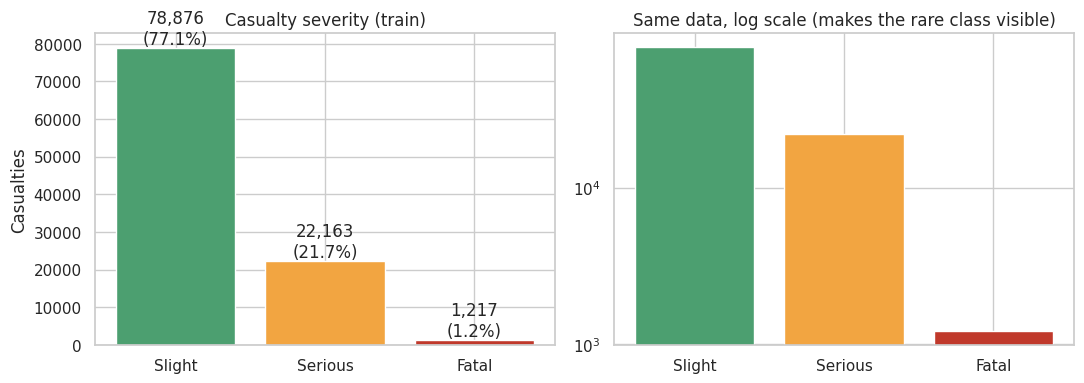

In [ ]:
order = ['Slight', 'Serious', 'Fatal']
counts = train_df['severity_label'].value_counts().reindex(order)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(order, counts.values, color=['#4c9f70', '#f2a541', '#c0392b'])
ax[0].set_title('Casualty severity (train)'); ax[0].set_ylabel('Casualties')
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f'{v:,}\n({v/counts.sum():.1%})', ha='center', va='bottom')
ax[1].bar(order, counts.values, color=['#4c9f70', '#f2a541', '#c0392b']); ax[1].set_yscale('log')
ax[1].set_title('Same data, log scale (makes the rare class visible)')
plt.tight_layout(); plt.show()

## Step 9: Numeric columns
Only a handful of columns are truly numeric. Check shape (skew), missingness, and whether the distribution differs by severity.

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,missing_%
age_of_casualty,100022.0,38.57,19.74,0.0,4.0,23.0,35.0,53.0,86.00,105.0,0.49,2.18
age_of_driver,96111.0,40.94,17.69,1.0,13.0,26.0,38.0,54.0,85.00,105.0,0.55,6.01
engine_capacity_cc,76847.0,1603.30,1228.70,12.0,123.0,1197.0,1498.0,1968.0,6751.08,16400.0,4.62,24.85
number_of_vehicles,102256.0,1.88,0.75,1.0,1.0,1.0,2.0,2.0,4.00,17.0,1.95,0.00
number_of_casualties,102256.0,1.83,5.41,1.0,1.0,1.0,1.0,2.0,6.00,142.0,24.31,0.00


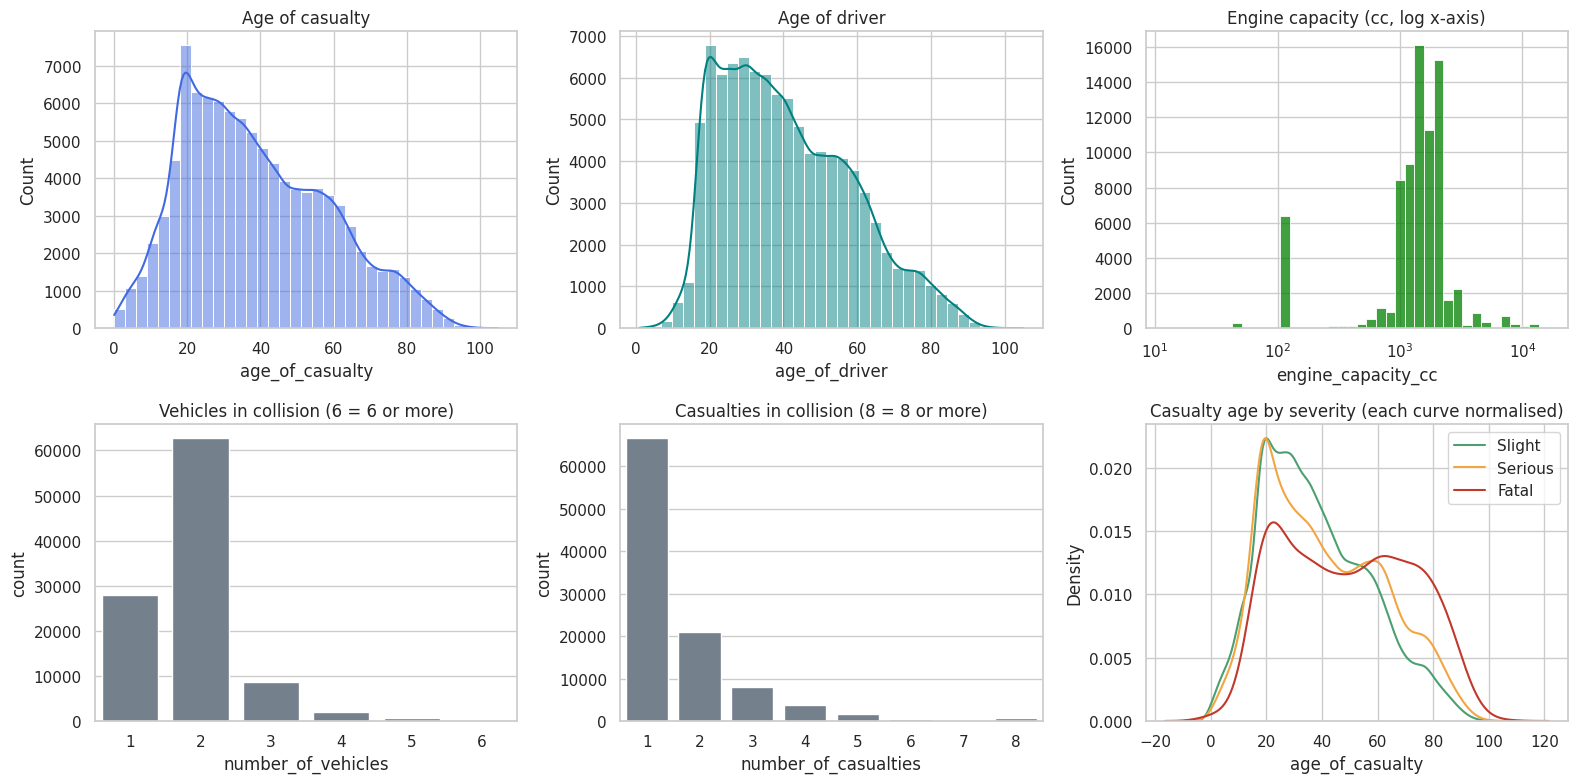

,column,median_fatal,median_serious,median_slight,kruskal_H,p_value
0,age_of_casualty,48.0,37.0,35.0,490.0157,0.0
1,age_of_driver,44.0,39.0,38.0,98.9861,0.0
2,engine_capacity_cc,1395.0,1396.0,1498.0,434.6183,0.0
3,number_of_vehicles,2.0,2.0,2.0,986.1011,0.0
4,number_of_casualties,1.0,1.0,1.0,463.6047,0.0


In [ ]:
num_view = ['age_of_casualty', 'age_of_driver', 'engine_capacity_cc', 'number_of_vehicles', 'number_of_casualties']
desc = train_df[num_view].describe(percentiles=[.01, .25, .5, .75, .99]).T
desc['skew'] = train_df[num_view].skew()
desc['missing_%'] = train_df[num_view].isna().mean() * 100
display(desc.round(2))

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
sns.histplot(train_df['age_of_casualty'].dropna(), bins=35, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].set_title('Age of casualty')
sns.histplot(train_df['age_of_driver'].dropna(), bins=35, kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Age of driver')
sns.histplot(train_df['engine_capacity_cc'].dropna(), bins=40, log_scale=True, ax=axes[0, 2], color='green')
axes[0, 2].set_title('Engine capacity (cc, log x-axis)')
sns.countplot(x=train_df['number_of_vehicles'].clip(upper=6), ax=axes[1, 0], color='slategray')
axes[1, 0].set_title('Vehicles in collision (6 = 6 or more)')
sns.countplot(x=train_df['number_of_casualties'].clip(upper=8), ax=axes[1, 1], color='slategray')
axes[1, 1].set_title('Casualties in collision (8 = 8 or more)')
for sev, col in [('Slight', '#4c9f70'), ('Serious', '#f2a541'), ('Fatal', '#c0392b')]:
    sns.kdeplot(train_df.loc[train_df.severity_label == sev, 'age_of_casualty'].dropna(),
                ax=axes[1, 2], label=sev, color=col, common_norm=False)
axes[1, 2].set_title('Casualty age by severity (each curve normalised)'); axes[1, 2].legend()
plt.tight_layout(); plt.show()

# Do the distributions differ by severity? Medians + Kruskal-Wallis (rank-based, no normality assumption)
rows = []
for c in num_view:
    groups = [train_df.loc[train_df[TARGET] == k, c].dropna() for k in (1, 2, 3)]
    h, p = stats.kruskal(*groups)
    rows.append({'column': c, 'median_fatal': groups[0].median(), 'median_serious': groups[1].median(),
                 'median_slight': groups[2].median(), 'kruskal_H': h, 'p_value': p})
display(pd.DataFrame(rows).round(4))

## Step 10: Categorical columns, ranked for attention
With ~100k rows, almost any difference is "statistically significant", so the p-value tells you little.
First see how many categories each column has and how dominant the top category is.

In [ ]:
cat_cols = [c for c in roles[roles.isin(['nominal', 'ordinal'])].index if c in train_df.columns]
overview = pd.DataFrame({
    'role': roles[cat_cols],
    'n_unique': train_df[cat_cols].nunique(),
    'top_category_share_%': [train_df[c].value_counts(normalize=True).iloc[0] * 100 for c in cat_cols],
    'missing_%': train_df[cat_cols].isna().mean() * 100}).round(1)
overview.sort_values('top_category_share_%', ascending=False)

,role,n_unique,top_category_share_%,missing_%
pedestrian_road_maintenance_worker,nominal,3,99.9,13.6
towing_and_articulation,nominal,6,99.4,3.7
escooter_flag_cas,nominal,2,99.1,0.0
escooter_flag_veh,nominal,2,98.9,0.0
vehicle_left_hand_drive,nominal,2,98.7,6.8
bus_or_coach_passenger,nominal,5,98.5,0.2
carriageway_hazards,nominal,12,95.6,5.1
vehicle_location_restricted_lane,nominal,7,94.9,8.5
hit_object_in_carriageway,nominal,12,92.4,7.9
trunk_road_flag,nominal,2,91.9,7.5


### Severity profile: how often vs how dangerous
Left panel: how common each category is. Right panel: what share of its casualties are Serious or Fatal.
A category can be rare and deadly, or common and harmless; you need both views.
Categories with fewer than `min_n` casualties are hidden so tiny groups don't create misleading bars.
Labels come from the DfT guide (`LABELS`); missing values appear as their own bar.

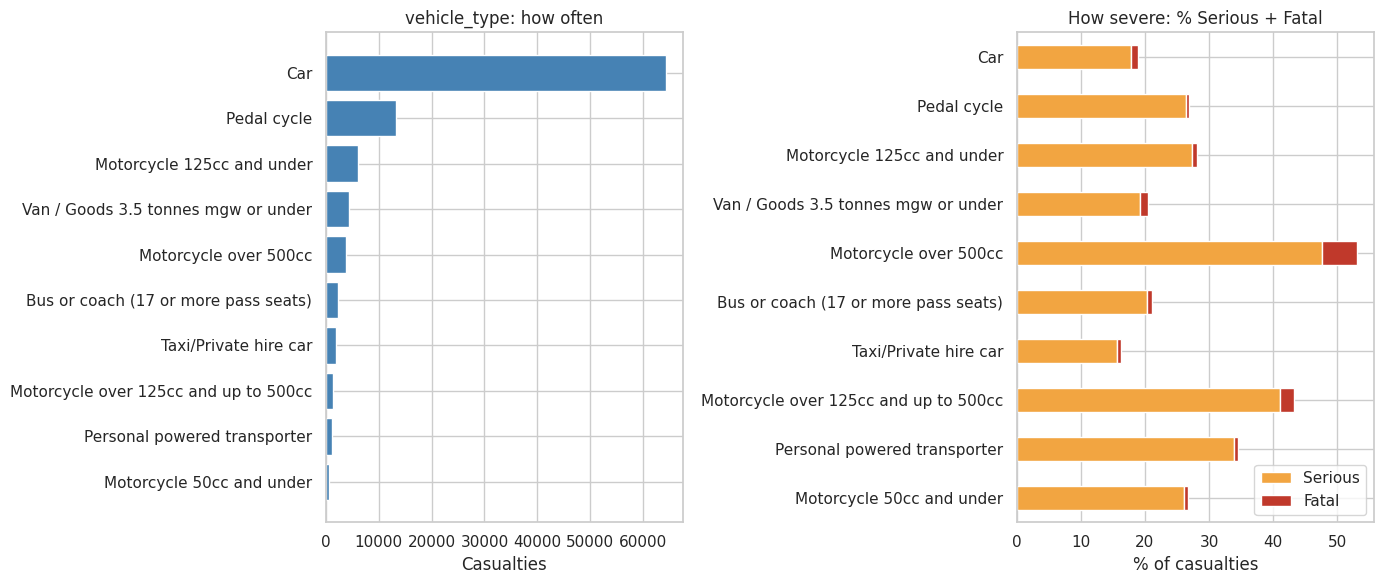

,Fatal,Serious,Slight,n
Car,1.1,17.9,81.1,64269
Pedal cycle,0.5,26.4,73.1,13364
Motorcycle 125cc and under,0.7,27.3,71.9,6115
Van / Goods 3.5 tonnes mgw or under,1.2,19.3,79.5,4402
Motorcycle over 500cc,5.5,47.6,46.9,3944
Bus or coach (17 or more pass seats),0.8,20.3,78.9,2294
Taxi/Private hire car,0.6,15.7,83.7,1903
Motorcycle over 125cc and up to 500cc,2.2,41.0,56.8,1371
Personal powered transporter,0.6,33.9,65.5,1179
Motorcycle 50cc and under,0.6,26.1,73.3,633


In [ ]:
def severity_profile(df, col, top_n=10, min_n=100, sort='n', label_map=None):
    """Left: how often each category occurs. Right: share of Serious + Fatal.
    sort='n' orders by frequency; sort='code' keeps natural order (ages, hours, days)."""
    label_map = dict(label_map or LABELS.get(col, {}))
    label_map[-99] = 'Unknown / missing'
    tmp = df[[col, TARGET]].copy()
    tmp[col] = tmp[col].fillna(-99)                     # missing shown as its own bar
    ct = pd.crosstab(tmp[col], tmp[TARGET].map({1: 'Fatal', 2: 'Serious', 3: 'Slight'}))
    for k in ['Fatal', 'Serious', 'Slight']:
        if k not in ct:
            ct[k] = 0
    ct['n'] = ct.sum(axis=1)
    ct = ct[ct.n >= min_n]
    ct = ct.sort_values('n', ascending=False).head(top_n) if sort == 'n' else ct.sort_index().head(top_n)
    pct = ct[['Fatal', 'Serious', 'Slight']].div(ct.n, axis=0) * 100
    names = [str(label_map.get(i, i))[:42] for i in ct.index]
    ct.index = names
    pct.index = names

    fig, ax = plt.subplots(1, 2, figsize=(14, max(3, 0.45 * len(ct) + 1.5)))
    ax[0].barh(names, ct.n, color='steelblue'); ax[0].invert_yaxis()
    ax[0].set_title(f'{col}: how often'); ax[0].set_xlabel('Casualties')
    pct[['Serious', 'Fatal']].plot.barh(stacked=True, ax=ax[1], color=['#f2a541', '#c0392b'])
    ax[1].invert_yaxis(); ax[1].set_title('How severe: % Serious + Fatal')
    ax[1].set_xlabel('% of casualties'); ax[1].set_ylabel('')
    ax[1].legend(title='', loc='lower right')
    plt.tight_layout(); plt.show()
    return pct.round(1).join(ct.n)

PRIORITY = ['vehicle_type', 'casualty_type', 'casualty_class', 'speed_limit', 'light_conditions',
            'road_type', 'urban_or_rural_area', 'weather_conditions', 'road_surface_conditions',
            'first_point_of_impact', 'junction_detail', 'sex_of_casualty']
ORDERED  = ['age_band_of_casualty', 'hour', 'day_of_week', 'month']   # natural order, not by frequency

# Start with one; run the loops in the next cell when you want the full set
severity_profile(train_df, 'vehicle_type')

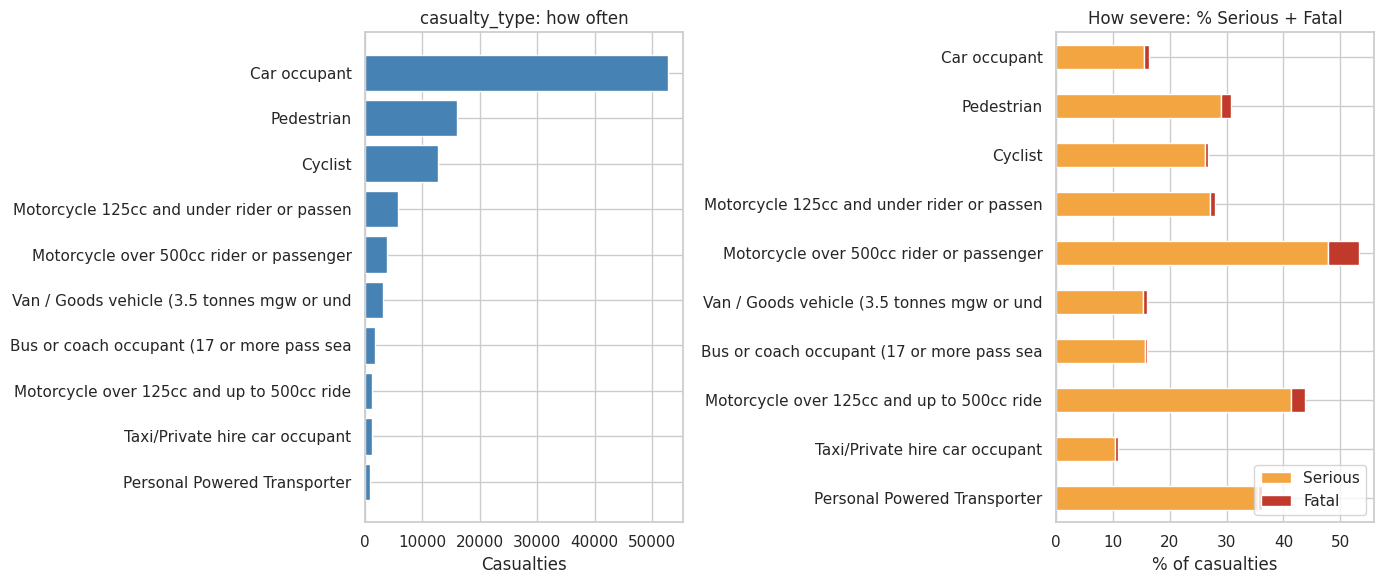

,Fatal,Serious,Slight,n
Car occupant,0.9,15.5,83.6,52735
Pedestrian,1.8,29.1,69.2,15983
Cyclist,0.5,26.2,73.3,12802
Motorcycle 125cc and under rider or passen,0.7,27.2,72.1,5852
Motorcycle over 500cc rider or passenger,5.5,47.8,46.8,3848
Van / Goods vehicle (3.5 tonnes mgw or und,0.8,15.3,83.9,3179
Bus or coach occupant (17 or more pass sea,0.2,15.8,84.0,1701
Motorcycle over 125cc and up to 500cc ride,2.3,41.4,56.3,1302
Taxi/Private hire car occupant,0.5,10.4,89.1,1266
Personal Powered Transporter,0.7,35.6,63.7,984


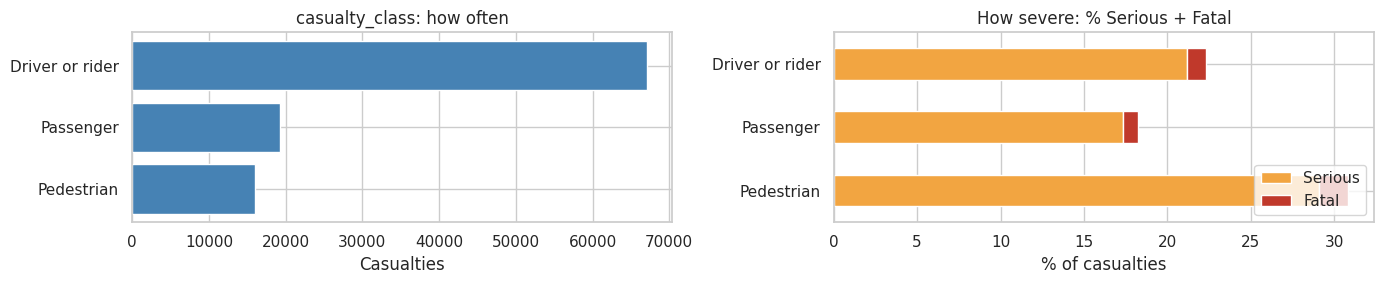

,Fatal,Serious,Slight,n
Driver or rider,1.1,21.1,77.7,67064
Passenger,0.9,17.4,81.8,19209
Pedestrian,1.8,29.1,69.2,15983


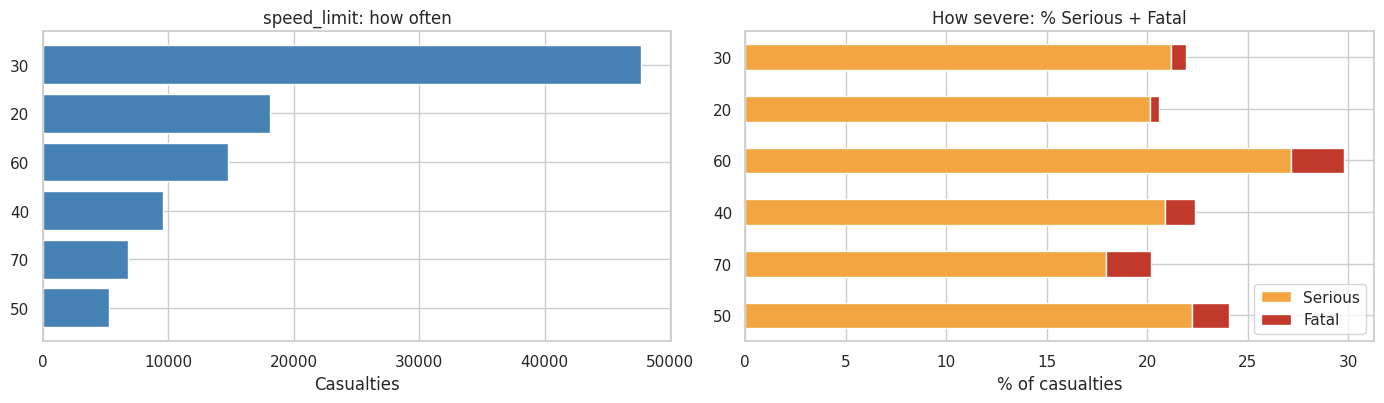

,Fatal,Serious,Slight,n
30,0.7,21.2,78.1,47694
20,0.5,20.1,79.4,18119
60,2.6,27.2,70.2,14793
40,1.5,20.9,77.6,9592
70,2.2,17.9,79.8,6800
50,1.8,22.2,75.9,5258


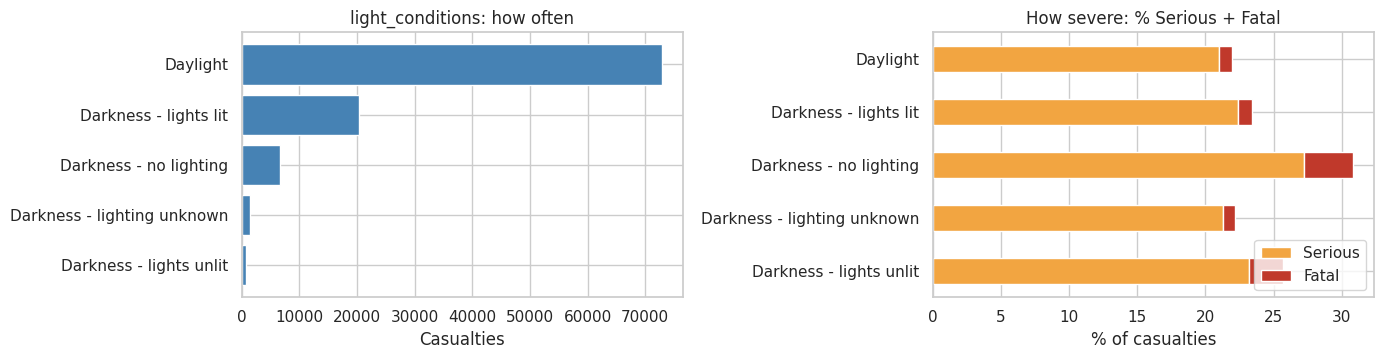

,Fatal,Serious,Slight,n
Daylight,1.0,21.0,78.0,72902
Darkness - lights lit,1.1,22.4,76.6,20417
Darkness - no lighting,3.6,27.2,69.2,6720
Darkness - lighting unknown,0.9,21.3,77.8,1482
Darkness - lights unlit,2.5,23.2,74.3,716


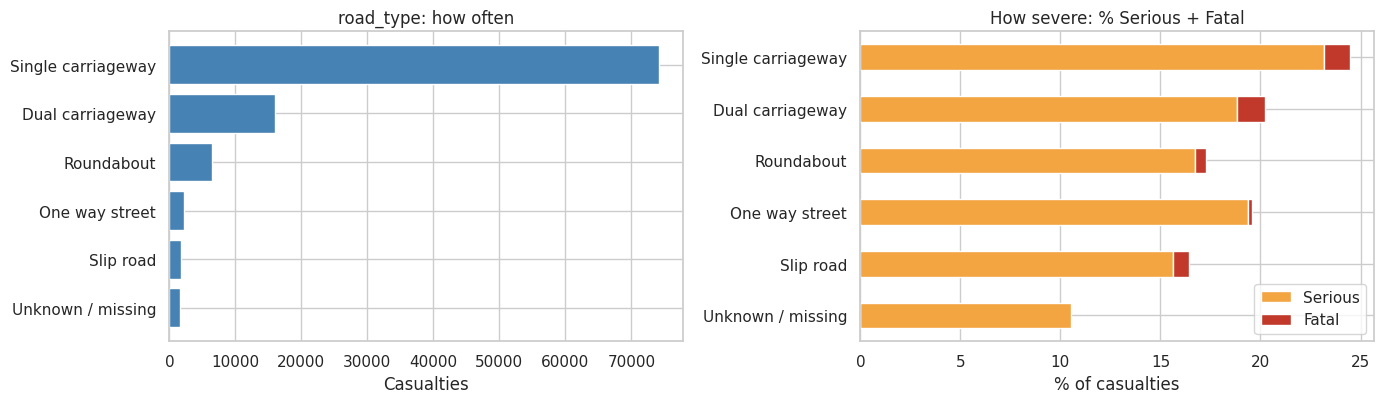

,Fatal,Serious,Slight,n
Single carriageway,1.3,23.2,75.5,74111
Dual carriageway,1.4,18.8,79.8,16021
Roundabout,0.6,16.7,82.7,6424
One way street,0.2,19.4,80.4,2278
Slip road,0.8,15.6,83.6,1752
Unknown / missing,0.0,10.5,89.5,1670


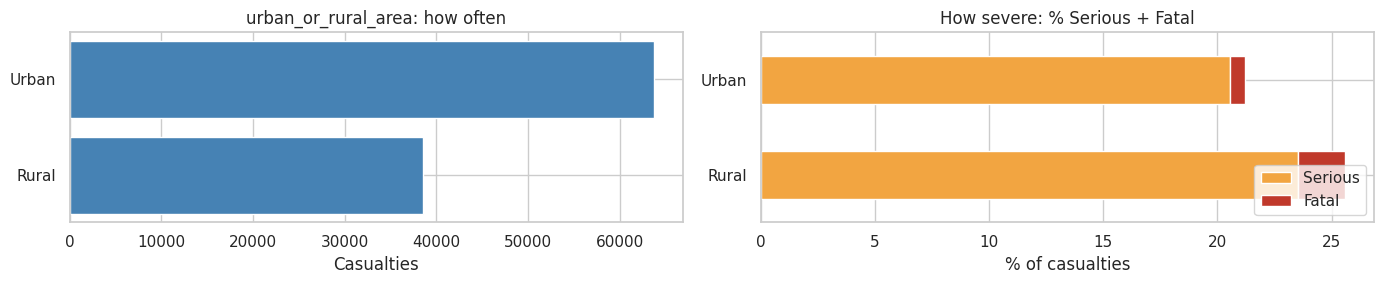

,Fatal,Serious,Slight,n
Urban,0.7,20.6,78.8,63724
Rural,2.1,23.5,74.4,38527


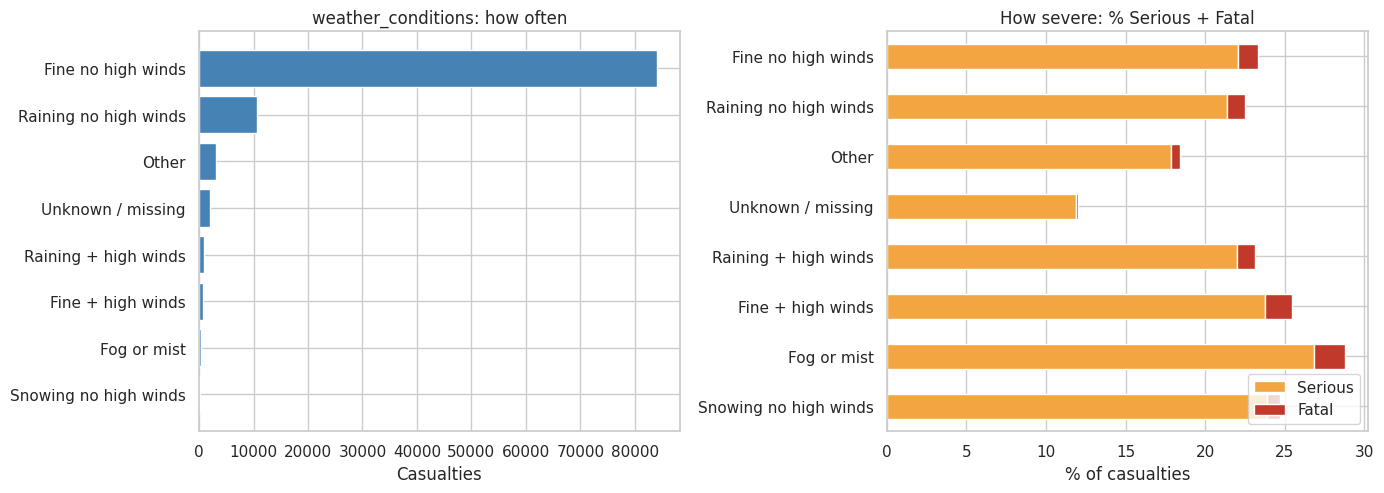

,Fatal,Serious,Slight,n
Fine no high winds,1.2,22.1,76.7,84056
Raining no high winds,1.1,21.3,77.5,10708
Other,0.6,17.9,81.6,3182
Unknown / missing,0.1,11.9,88.0,2044
Raining + high winds,1.1,22.0,76.9,883
Fine + high winds,1.7,23.7,74.5,750
Fog or mist,1.9,26.8,71.2,365
Snowing no high winds,0.8,23.9,75.3,251


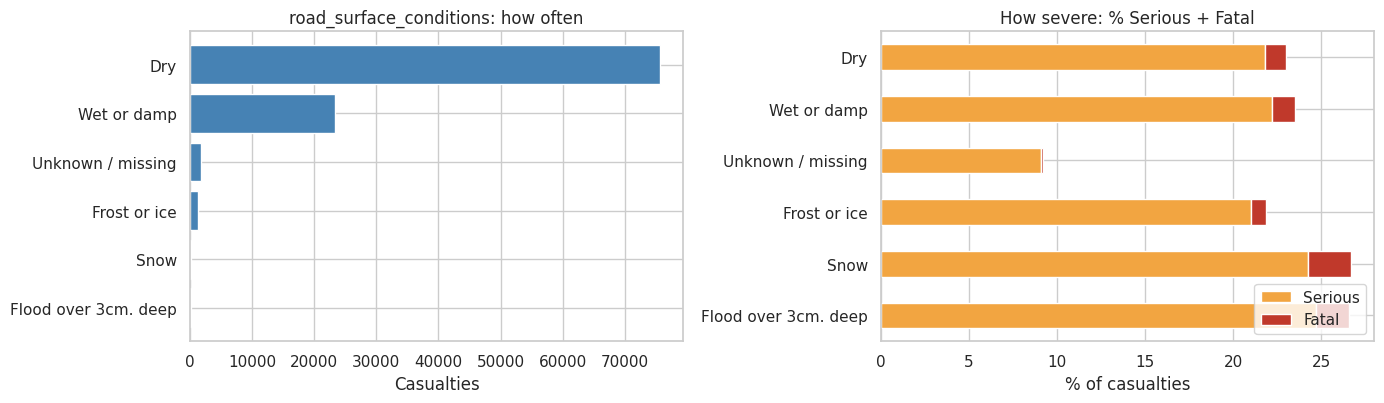

,Fatal,Serious,Slight,n
Dry,1.2,21.8,77.0,75597
Wet or damp,1.3,22.2,76.5,23411
Unknown / missing,0.1,9.1,90.8,1708
Frost or ice,0.8,21.0,78.1,1217
Snow,2.4,24.2,73.3,165
Flood over 3cm. deep,1.9,24.7,73.4,158


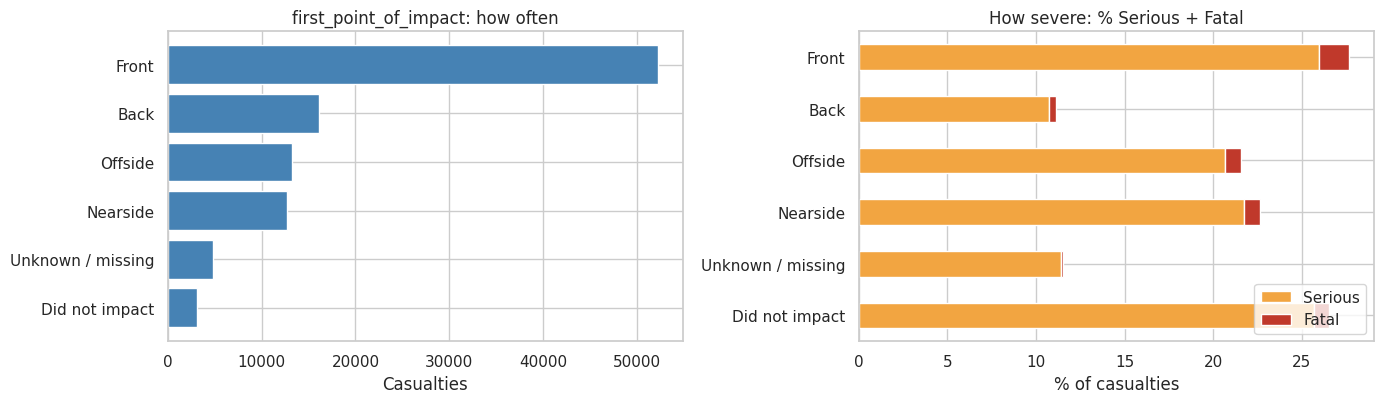

,Fatal,Serious,Slight,n
Front,1.7,26.0,72.3,52277
Back,0.4,10.7,88.9,16128
Offside,0.9,20.7,78.4,13191
Nearside,0.9,21.8,77.3,12677
Unknown / missing,0.1,11.4,88.5,4822
Did not impact,0.8,25.7,73.5,3161


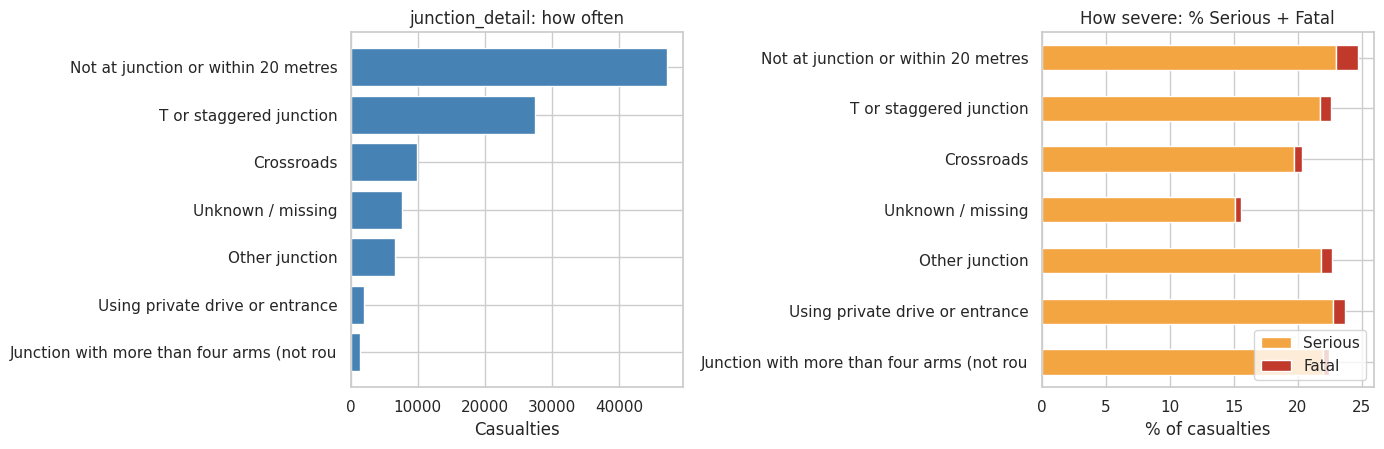

,Fatal,Serious,Slight,n
Not at junction or within 20 metres,1.7,23.0,75.3,47094
T or staggered junction,0.8,21.8,77.4,27473
Crossroads,0.6,19.7,79.6,9867
Unknown / missing,0.5,15.1,84.4,7659
Other junction,0.9,21.8,77.3,6639
Using private drive or entrance,0.9,22.8,76.3,2055
Junction with more than four arms (not rou,0.5,22.0,77.5,1469


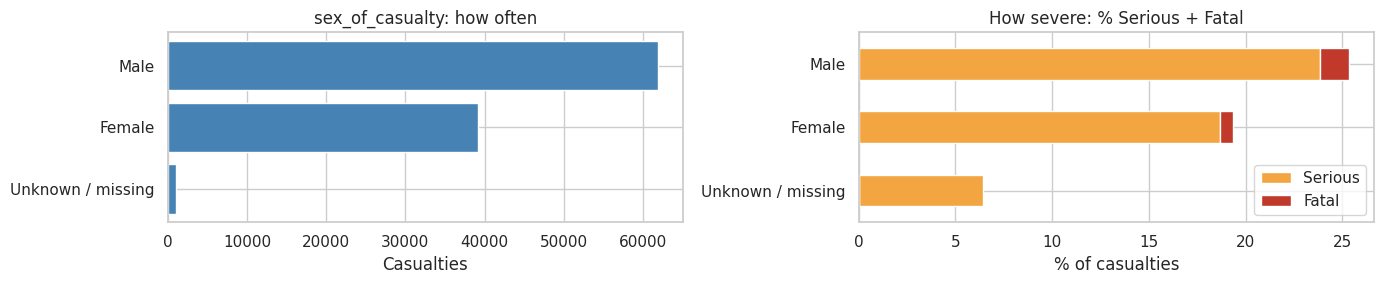

,Fatal,Serious,Slight,n
Male,1.5,23.8,74.6,61945
Female,0.7,18.7,80.6,39210
Unknown / missing,0.0,6.4,93.6,1101


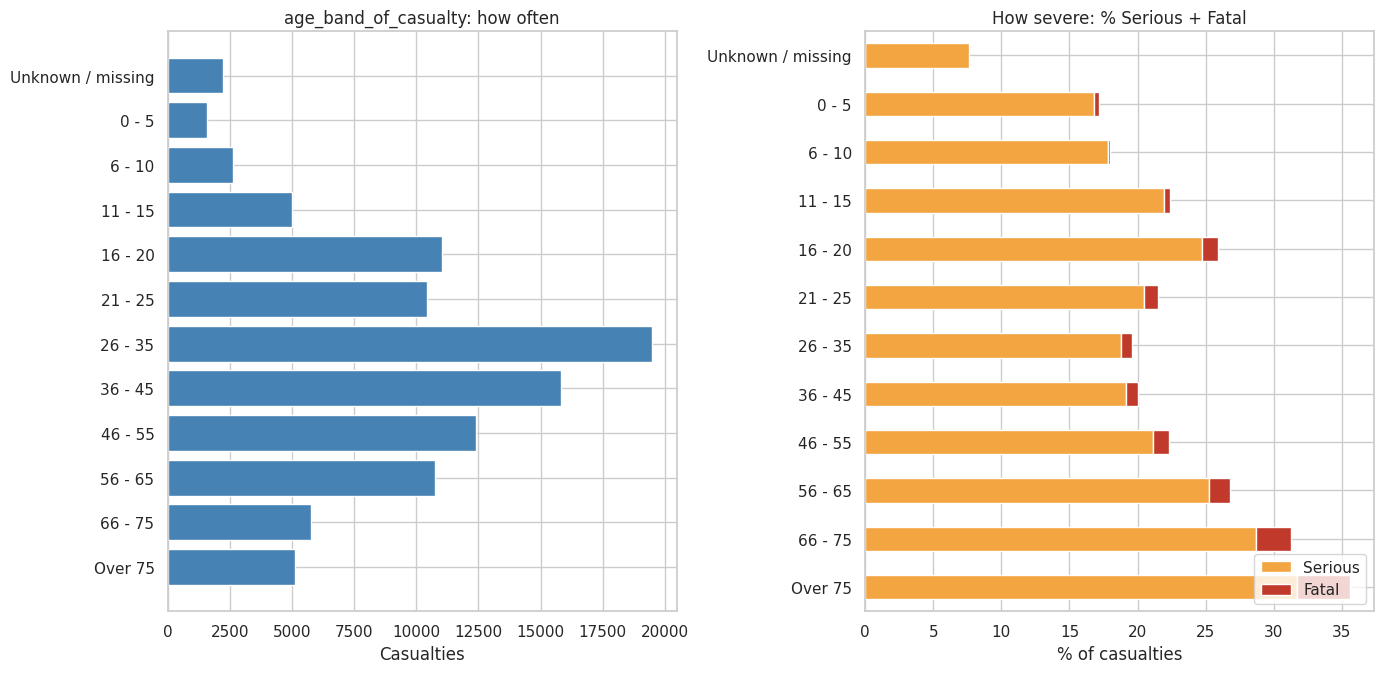

,Fatal,Serious,Slight,n
Unknown / missing,0.0,7.7,92.3,2234
0 - 5,0.4,16.8,82.8,1596
6 - 10,0.2,17.8,82.0,2645
11 - 15,0.4,22.0,77.6,4996
16 - 20,1.2,24.7,74.1,11021
21 - 25,1.1,20.4,78.5,10427
26 - 35,0.8,18.8,80.4,19494
36 - 45,0.9,19.2,80.0,15805
46 - 55,1.1,21.1,77.7,12398
56 - 65,1.6,25.2,73.2,10741


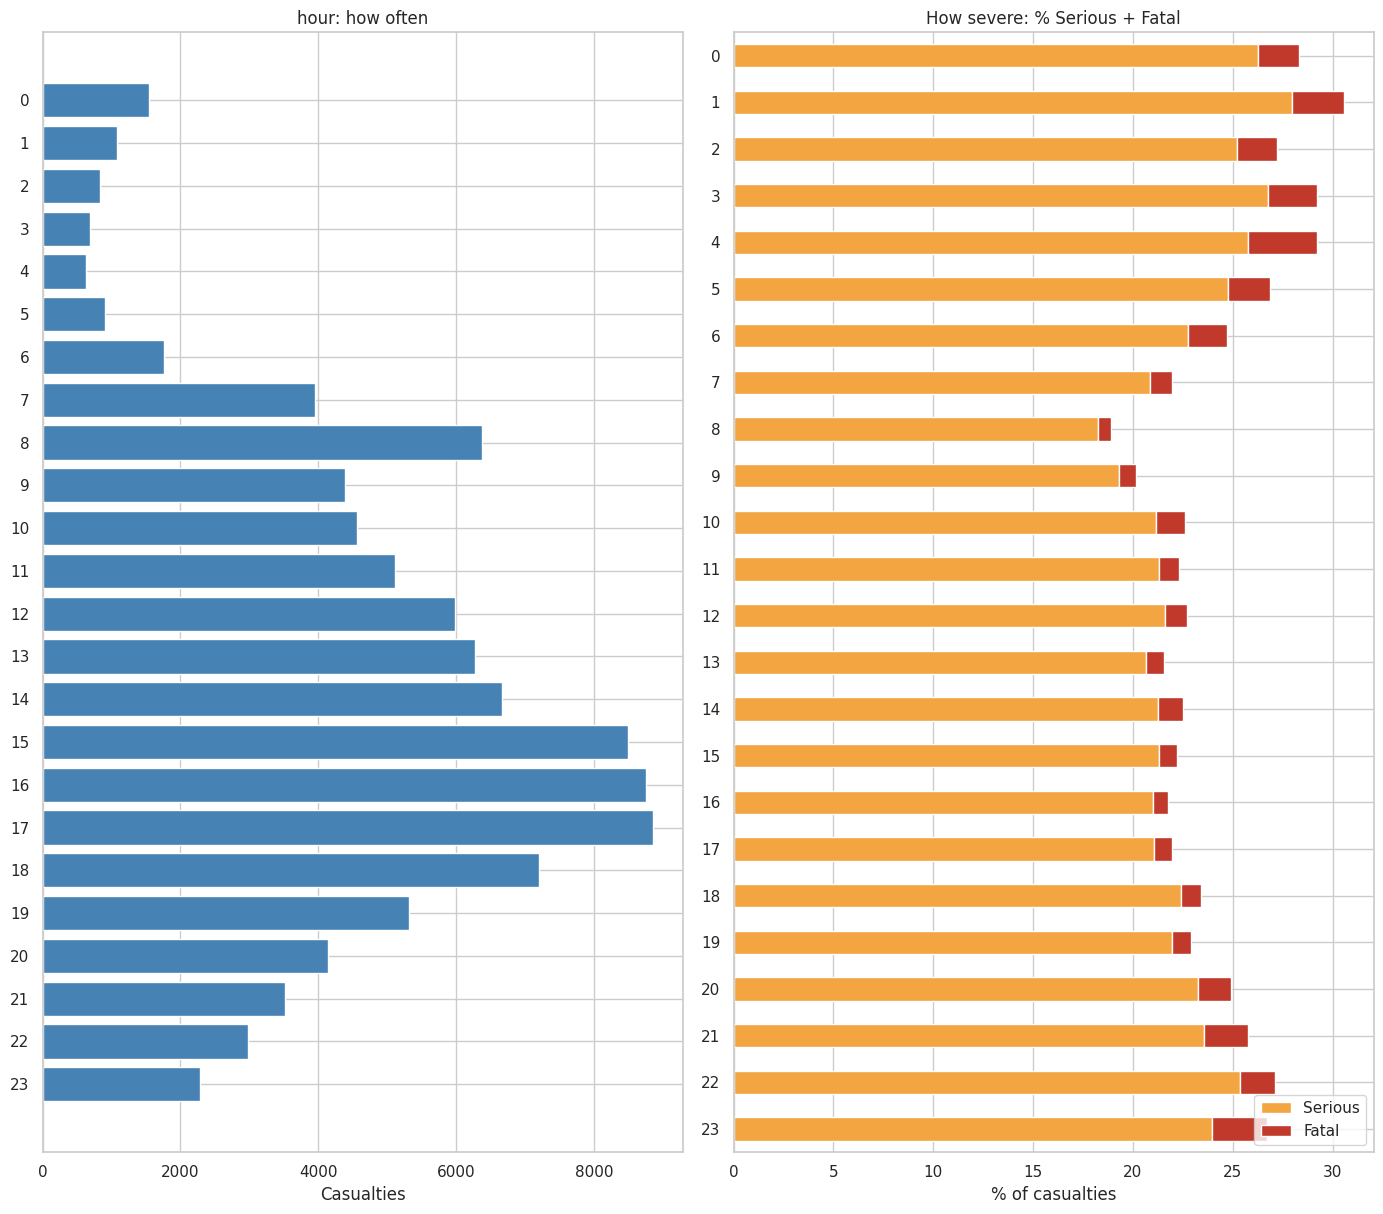

,Fatal,Serious,Slight,n
0,2.1,26.3,71.7,1549
1,2.6,27.9,69.5,1077
2,2.0,25.2,72.8,837
3,2.5,26.8,70.8,691
4,3.5,25.7,70.8,637
5,2.1,24.8,73.1,912
6,1.9,22.8,75.3,1760
7,1.1,20.9,78.0,3947
8,0.6,18.2,81.1,6369
9,0.8,19.3,79.9,4385


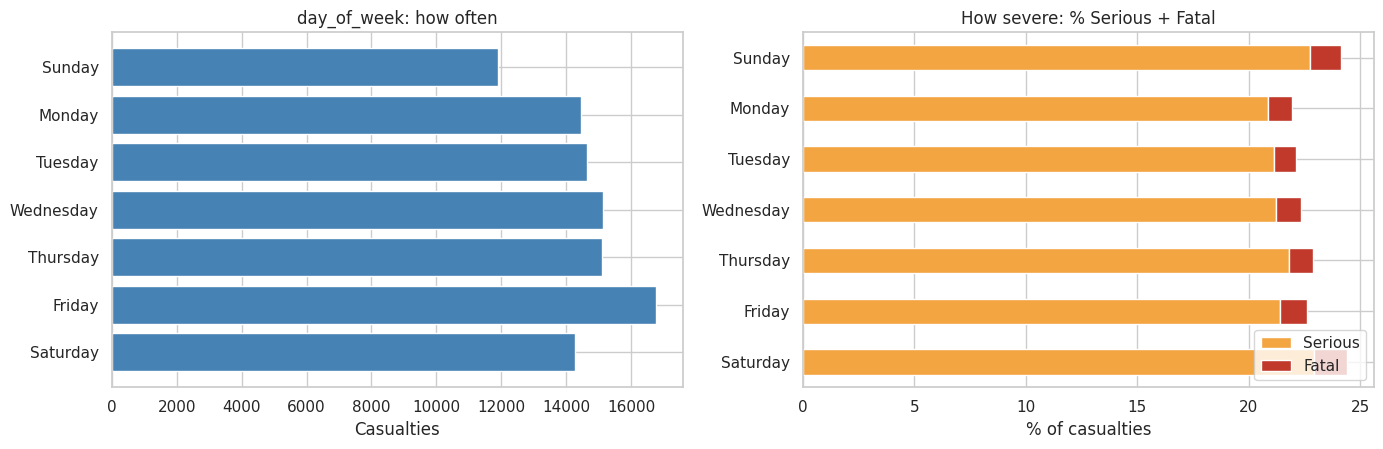

,Fatal,Serious,Slight,n
Sunday,1.4,22.7,75.9,11887
Monday,1.1,20.9,78.1,14459
Tuesday,1.0,21.1,77.9,14628
Wednesday,1.1,21.2,77.7,15144
Thursday,1.1,21.8,77.1,15109
Friday,1.2,21.4,77.4,16763
Saturday,1.5,22.9,75.6,14266


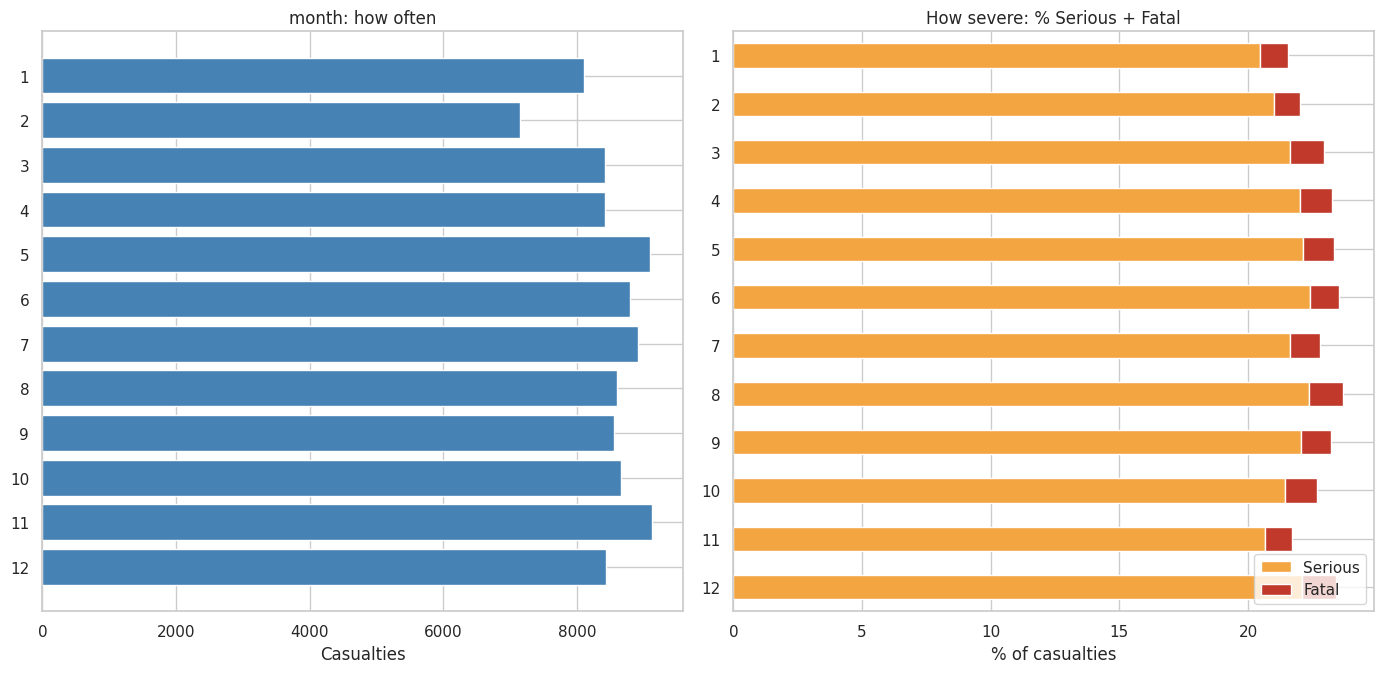

,Fatal,Serious,Slight,n
1,1.1,20.5,78.5,8099
2,1.0,21.0,78.0,7143
3,1.3,21.6,77.0,8418
4,1.3,22.0,76.7,8418
5,1.2,22.1,76.6,9090
6,1.1,22.4,76.5,8799
7,1.2,21.6,77.2,8914
8,1.3,22.4,76.3,8604
9,1.2,22.1,76.8,8550
10,1.3,21.4,77.3,8662


In [ ]:
# Full set (16 figures). Share the images and we will read them together.
for c in PRIORITY[1:]:
    display(severity_profile(train_df, c))
for c in ORDERED:
    display(severity_profile(train_df, c, top_n=24, min_n=50, sort='code'))